In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [2]:
df_meteo_mes = pd.read_parquet("../data/processed/datos_meteo_Valencia_91-25(month).parquet")
#df_meteo_anio = pd.read_parquet("../data/processed/datos_meteo_Valencia_91-25(year).parquet")

In [3]:
df_meteo_mes.head()

,temp_med_mar (Cº),temp_med_mes (Cº),temp_med_max (Cº),temp_med_min (Cº),temp_abs_max (Cº),temp_abs_min (Cº),dias_temp>30,total_precip_mes (mm),precip_max (mm),dias_precip>10mm,dias_precip>30mm,dias_lluvia,dias_granizo,dias_tormenta,humedad_med (%),presion_max (hPa),presion_min (hPa),presion_med (hPa),viento_vel_max (km/h),viento_vel_med (km/h)
1991-01,13.6,11.1,15.3,6.8,22.5,1.2,0,104.2,32.4,3,2,7,1,1,74.580645,1030.4,1013.4,1022.179301,45.4,20.441801
1991-02,12.5,10.9,15.1,6.6,21.5,0.4,0,67.7,29.5,2,0,7,0,1,74.302083,1028.3,997.6,1014.741815,49.9,19.540625
1991-03,13.4,14.5,18.9,10.1,26.6,6.0,0,82.7,46.0,2,1,15,0,0,76.641129,1025.8,984.3,1009.190591,40.3,16.776747
1991-04,14.5,14.7,19.5,9.8,24.5,5.6,0,37.5,14.9,2,0,10,0,1,70.225000,1023.7,999.2,1013.787639,52.7,16.190417
1991-05,16.5,16.2,21.3,11.0,27.5,6.0,0,21.3,5.4,0,0,8,0,1,66.404570,1030.7,1004.2,1015.025538,30.9,12.288844


In [4]:
df_temporada_critica = df_meteo_mes

In [5]:
#df_temporada_critica = df_meteo_mes[df_meteo_mes.index.month.isin([8, 9, 10, 11, 12])]

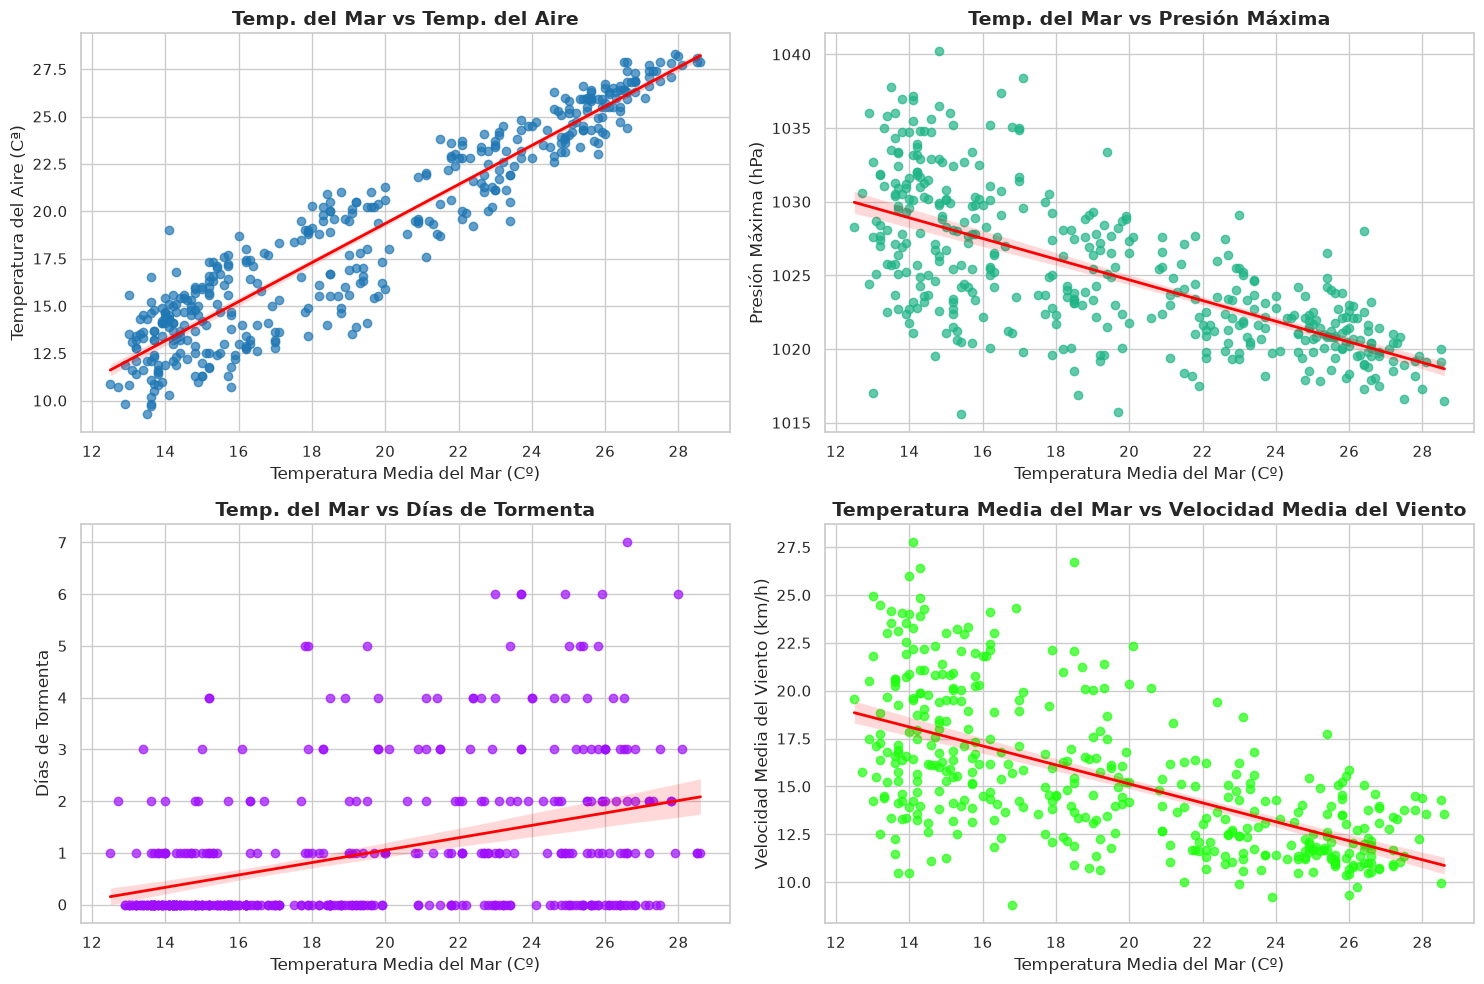

In [6]:
sns.set_theme(style="whitegrid")

fig = plt.figure(figsize=(15, 10))
gs = fig.add_gridspec(2, 2)

# GRÁFICO 1: temperatura media del mar vs presión máxima
ax1 = fig.add_subplot(gs[0, 0])
sns.regplot(
    data=df_temporada_critica, 
    x='temp_med_mar (Cº)', 
    y='temp_med_mes (Cº)', 
    ax=ax1,
    scatter_kws={'alpha': 0.7, 'color': '#1f77b4'},
    line_kws={'color': 'red', 'linewidth': 2}
)
ax1.set_title("Temp. del Mar vs Temp. del Aire", fontsize=14, fontweight='bold')
ax1.set_xlabel("Temperatura Media del Mar (Cº)")
ax1.set_ylabel("Temperatura del Aire (Cª)")

# GRÁFICO 2: temperatura media del mar vs presión máxima
ax2 = fig.add_subplot(gs[0, 1])
sns.regplot(
    data=df_temporada_critica, 
    x='temp_med_mar (Cº)', 
    y='presion_max (hPa)', 
    ax=ax2,
    scatter_kws={'alpha': 0.7, 'color': "#1fb487"},
    line_kws={'color': 'red', 'linewidth': 2}
)
ax2.set_title("Temp. del Mar vs Presión Máxima", fontsize=14, fontweight='bold')
ax2.set_xlabel("Temperatura Media del Mar (Cº)")
ax2.set_ylabel("Presión Máxima (hPa)")

# GRÁFICO 3: temperatura media del mar vs dias de tormenta
ax3 = fig.add_subplot(gs[1, 0])
sns.regplot(
    data=df_temporada_critica, 
    x='temp_med_mar (Cº)', 
    y='dias_tormenta', 
    ax=ax3,
    scatter_kws={'alpha': 0.7, 'color': "#9f0eff"}, 
    line_kws={'color': 'red', 'linewidth': 2}
)
ax3.set_title("Temp. del Mar vs Días de Tormenta", fontsize=14, fontweight='bold')
ax3.set_xlabel("Temperatura Media del Mar (Cº)")
ax3.set_ylabel("Días de Tormenta")

# GRÁFICO 4: temperatura media del mar vs Velocidad Media del Viento
ax4 = fig.add_subplot(gs[1, 1])
sns.regplot(
    data=df_temporada_critica, 
    x='temp_med_mar (Cº)', 
    y='viento_vel_med (km/h)', 
    ax=ax4,
    scatter_kws={'alpha': 0.7, 'color': "#1eff0e"},
    line_kws={'color': 'red', 'linewidth': 2}
)
ax4.set_title("Temperatura Media del Mar vs Velocidad Media del Viento", fontsize=14, fontweight='bold')
ax4.set_xlabel("Temperatura Media del Mar (Cº)")
ax4.set_ylabel("Velocidad Media del Viento (km/h)")


# # GRÁFICO 4 : Temp. Media del Mar vs Precipitación Total del Mes
# ax4 = fig.add_subplot(gs[1, 1])
# sns.regplot(
#     data=df_temporada_critica, 
#     x='temp_med_mar (Cº)', 
#     y='total_precip_mes (mm)', 
#     ax=ax4,
#     scatter_kws={'alpha': 0.7, 'color': '#2ca02c'}, # Tono verde
#     line_kws={'color': 'red', 'linewidth': 2}
# )
# ax4.set_title("Temp. del Mar vs Precipitación Total / Mes", fontsize=13, fontweight='bold')
# ax4.set_xlabel("Temperatura Media del Mar (Cº)")
# ax4.set_ylabel("Precipitación Total Mes (mm)")

# 3. Ajustamos espacios y mostramos
plt.tight_layout()
plt.show()